# Momentum Analysis and Stock Screening

## Summary

| | |
| :--- | :--- |
| **Idea** | Screen for stocks with strong 12-month momentum (excluding the last month), a smooth trend, a price above the 200-day average and a healthy RSI, and expect them to outperform. |
| **Verdict** | Rejected |
| **Result** | A one-year test of the screen's picks returned 11.1% against 49.5% for simply holding every ticker in the universe: alpha of -38 points, Sharpe 0.53 against 1.62, 60% win rate. |
| **Trust** | Medium for the rejection, low as a general statement about momentum. It is a single one-year window on 55 hand-picked tickers. The notebook's own conclusion is the durable part: the watchlist was already a selection of winners, and the filters added complexity without adding return. |
| **Date** | 2026-07-19 |
| **Code status** | Frozen: written before the current modules and no longer runs. Read it as a report. |

*Summary added 2026-10-13 by Claude from this notebook's own commentary and stored results. The verdict is a draft for Ben to confirm or correct.*

# Momentum Analysis and Stock Screening
This notebook identifies high-momentum stocks from local CSV data and screens for potential growth based on technical trends, stability, and risk-adjusted performance.

## 1. Load and Preprocess Local Data
We read the price data from `YF/yf-prices.csv`, ensure proper date formatting, and pivot the data to create a wide-format time-series for analysis.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import os

# Import project-specific classes
from Visualizer import Visualizer
from PriceData import PriceData

# Set plotting style
plt.style.use('seaborn-v0_8')
%matplotlib inline

DATA_FILE = 'YF/yf-prices.csv'

def load_and_preprocess():
    # Use PriceData class to ensure consistent loading across notebooks
    pd_loader = PriceData(DATA_FILE)
    
    # Check if 'adj_close' exists, otherwise fallback to 'close'
    # Based on the scraper logic, 'adj_close' might be missing in some versions of the CSV
    available_cols = pd_loader.df.columns
    price_col = 'adj_close' if 'adj_close' in available_cols else 'close'
    print(f"Using column '{price_col}' for price analysis.")
    
    # Get standard wide data for price
    prices = pd_loader.get_data_wide(price_col=price_col)
    
    # Manually pivot volume as PriceData doesn't have a wide volume helper yet
    df = pd_loader.df
    volume = df.pivot(index='date', columns='ticker', values='volume')
    volume.index = pd.to_datetime(volume.index)
    volume = volume.sort_index()
    
    print(f"Loaded data for {len(prices.columns)} tickers from {prices.index.min().date()} to {prices.index.max().date()}")
    return prices, volume

prices_df, volume_df = load_and_preprocess()
prices_df.tail()

Using column 'close' for price analysis.
Loaded data for 55 tickers from 2000-01-03 to 2026-07-17


ticker,AAPL,ADBE,ADI,ALNY,AMAT,AMD,AMGN,AMZN,ANET,ARM,...,SAP,SMCI,SNOW,SRPT,TSLA,TSM,TXN,VRT,VRTX,VST
date,,,,,,,,,,,,,,,,,,,,,
2026-07-13,317.309998,230.610001,386.010010,288.059998,575.390015,534.390015,360.450012,247.309998,181.149994,298.989990,...,159.970001,27.660000,268.649994,18.820000,394.760010,421.579987,298.570007,305.869995,480.250000,158.119995
2026-07-14,314.859985,220.779999,392.750000,281.260010,595.700012,548.130005,355.250000,247.490005,182.570007,281.170013,...,154.809998,27.650000,275.940002,17.959999,396.179993,420.390015,305.549988,303.579987,476.309998,158.429993
2026-07-15,327.500000,224.559998,390.959991,279.140015,579.429993,529.140015,358.320007,254.960007,171.919998,277.010010,...,155.910004,26.889999,271.869995,17.610001,394.459991,419.480011,301.190002,304.570007,477.079987,160.229996
2026-07-16,333.260010,235.309998,380.529999,283.149994,560.929993,500.940002,371.579987,249.889999,168.559998,262.010010,...,161.639999,24.680000,270.019989,17.230000,391.059998,409.739990,291.220001,294.109985,486.029999,152.559998
2026-07-17,333.739990,237.250000,375.359985,267.470001,529.659973,495.760010,366.290009,247.229996,168.610001,267.190002,...,159.039993,24.180000,268.899994,17.219999,380.839996,398.369995,284.019989,289.559998,485.649994,155.440002


## 2. Calculate Momentum Metrics
We compute returns for various lookback periods. A key metric is the "momentum factor", often defined as the 12-month return excluding the most recent month to account for short-term mean reversion:
$$Return_{12m\_ex\_1m} = \frac{P_{t-21}}{P_{t-252}} - 1$$

In [16]:
def calculate_momentum(prices, lookback_days=[63, 126, 252]):
    """
    lookback_days: list of trading days (e.g., 63 for ~3m, 126 for ~6m, 252 for ~1y)
    """
    momentum_metrics = pd.DataFrame(index=prices.columns)
    
    # Calculate simple returns for various periods
    for days in lookback_days:
        label = f"{days/21:.0f}m_return"
        # Handle cases where we don't have enough history
        if len(prices) >= days:
            momentum_metrics[label] = prices.iloc[-1] / prices.iloc[-days] - 1
        else:
            momentum_metrics[label] = np.nan
        
    # Calculate 12-month momentum excluding the most recent month (21 trading days)
    if len(prices) >= 252:
        momentum_metrics["12m_ex_1m"] = prices.iloc[-21] / prices.iloc[-252] - 1
    else:
        momentum_metrics["12m_ex_1m"] = np.nan
    
    return momentum_metrics

momentum_df = calculate_momentum(prices_df)
momentum_df.sort_values("12m_ex_1m", ascending=False).head(10)

,3m_return,6m_return,12m_return,12m_ex_1m
ticker,,,,
MU,0.865537,1.522968,6.506461,8.222523
INTC,0.387445,0.966887,3.168421,4.311404
MRVL,0.351038,1.349104,1.625774,3.028403
LRCX,0.170777,0.442384,2.123446,2.730390
DELL,1.022724,2.337002,2.248034,2.436357
AMD,0.780811,1.175149,2.090580,2.194813
AMAT,0.334358,0.662030,1.767935,2.098524
ARM,0.602531,1.542004,0.699898,1.664970
ASML,0.199751,0.316992,1.364413,1.527107


## 3. Risk-Adjusted Performance Calculation
High returns are great, but "clean" momentum is better. We calculate the $R^2$ of a linear regression on log-prices over the last year to identify stocks with steady trends versus volatile spikes.

In [17]:
def calculate_momentum_quality(prices, window=252):
    """
    Calculate the smoothness of the trend using R-squared of log prices.
    """
    quality_metrics = pd.DataFrame(index=prices.columns)
    r2_values = []
    vol_values = []
    
    last_year_prices = prices.tail(window)
    
    for ticker in prices.columns:
        y_series = last_year_prices[ticker].dropna()
        if len(y_series) < window * 0.8:
            r2_values.append(np.nan)
            vol_values.append(np.nan)
            continue
            
        y = np.log(y_series)
        x = np.arange(len(y))
        slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
        r2_values.append(r_value**2)
        
        # Volatility (standard deviation of daily returns)
        returns = y_series.pct_change().dropna()
        vol_values.append(returns.std() * np.sqrt(252)) # Annualized Vol
        
    quality_metrics["r_squared"] = r2_values
    quality_metrics["annualized_vol"] = vol_values
    
    return quality_metrics

quality_df = calculate_momentum_quality(prices_df)
metrics_df = pd.concat([momentum_df, quality_df], axis=1)
metrics_df["adj_momentum_score"] = metrics_df["12m_ex_1m"] * metrics_df["r_squared"]
metrics_df.sort_values("adj_momentum_score", ascending=False).head(10)

,3m_return,6m_return,12m_return,12m_ex_1m,r_squared,annualized_vol,adj_momentum_score
ticker,,,,,,,
MU,0.865537,1.522968,6.506461,8.222523,0.956658,0.765393,7.866141
INTC,0.387445,0.966887,3.168421,4.311404,0.879828,0.773588,3.793293
LRCX,0.170777,0.442384,2.123446,2.730390,0.955845,0.593094,2.609829
MRVL,0.351038,1.349104,1.625774,3.028403,0.676406,0.760933,2.048429
AMAT,0.334358,0.662030,1.767935,2.098524,0.950733,0.561123,1.995136
AMD,0.780811,1.175149,2.090580,2.194813,0.694909,0.690081,1.525195
ASML,0.199751,0.316992,1.364413,1.527107,0.933633,0.451103,1.425757
DELL,1.022724,2.337002,2.248034,2.436357,0.581649,0.685314,1.417105
VRT,-0.057655,0.678968,1.210791,1.424724,0.892030,0.616473,1.270897


## 4. Moving Average and Volume Filtering
We ensure the trend is robust by checking if the current price is above the 200-day Moving Average and if recent trading volume is healthy.

In [18]:
def apply_technical_filters(prices, volume):
    filters = pd.DataFrame(index=prices.columns)
    
    # 200-day Moving Average
    ma200 = prices.rolling(window=200).mean().iloc[-1]
    filters["above_ma200"] = prices.iloc[-1] > ma200
    
    # Relative Volume (last 5 days vs last 50 days)
    avg_vol_short = volume.tail(5).mean()
    avg_vol_long = volume.tail(50).mean()
    filters["rel_volume"] = avg_vol_short / avg_vol_long
    
    return filters

filters_df = apply_technical_filters(prices_df, volume_df)
final_df = pd.concat([metrics_df, filters_df], axis=1)

## 5. Calculate scores for all tickers


In [24]:
# Calculate metrics for all tickers
all_metrics = final_df.copy()
all_metrics = all_metrics.sort_values("adj_momentum_score", ascending=False)

print(f"Calculated momentum metrics for {len(all_metrics)} tickers.")
all_metrics.head(10)

Calculated momentum metrics for 55 tickers.


,3m_return,6m_return,12m_return,12m_ex_1m,r_squared,annualized_vol,adj_momentum_score,above_ma200,rel_volume
ticker,,,,,,,,,
MU,0.865537,1.522968,6.506461,8.222523,0.956658,0.765393,7.866141,True,0.848463
INTC,0.387445,0.966887,3.168421,4.311404,0.879828,0.773588,3.793293,True,0.852948
LRCX,0.170777,0.442384,2.123446,2.730390,0.955845,0.593094,2.609829,True,0.925227
MRVL,0.351038,1.349104,1.625774,3.028403,0.676406,0.760933,2.048429,True,0.595507
AMAT,0.334358,0.662030,1.767935,2.098524,0.950733,0.561123,1.995136,True,0.792894
AMD,0.780811,1.175149,2.090580,2.194813,0.694909,0.690081,1.525195,True,0.796614
ASML,0.199751,0.316992,1.364413,1.527107,0.933633,0.451103,1.425757,True,1.271837
DELL,1.022724,2.337002,2.248034,2.436357,0.581649,0.685314,1.417105,True,0.799036
VRT,-0.057655,0.678968,1.210791,1.424724,0.892030,0.616473,1.270897,True,0.719215


## 6. Visualize Momentum Profiles
Comparing the price action of top performers to visualize the acceleration.

In [25]:
def plot_momentum_results(prices, metrics_df, n=5):
    # Filter for technical sanity before plotting top performers
    top_performers = metrics_df[
        (metrics_df['above_ma200'] == True) & 
        (metrics_df['12m_ex_1m'] > 0)
    ].head(n)
    
    if top_performers.empty:
        print("No candidates found to plot.")
        return
        
    top_tickers = top_performers.index.tolist()
    
    # Normalizing data for comparison (last 252 trading days)
    plot_data = prices[top_tickers].tail(252)
    normalized_data = plot_data / plot_data.iloc[0] * 100
    
    Visualizer.plot_timeseries_zoom(
        normalized_data, 
        tickers=top_tickers,
        title='Top Momentum Performers (Normalized to 100)',
        ylabel='Relative Performance'
    )

plot_momentum_results(prices_df, all_metrics)


### Perform a Health Check:
*   **RSI < 30**: Extremely oversold (potential dip-buying opportunity).
*   **RSI > 70**: Still overbought despite the pullback.
*   **Drawdown (-5% to -15%)**: Standard bull-market consolidation.
*   **Dist to MA200 > 0**: Long term trend is still structurally bullish. If this approaches 0%, we are at a critical "make or break" support level.


In [29]:
def calculate_trend_health(prices, tickers):
    health_metrics = pd.DataFrame(index=tickers)
    
    for t in tickers:
        p = prices[t].dropna()
        if len(p) < 30: continue
        
        # 1. RSI (14-day)
        delta = p.diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
        # Handle division by zero
        loss = loss.mask(loss == 0, np.nan)
        rs = gain / loss
        current_rsi = 100 - (100 / (1 + rs.iloc[-1]))
        health_metrics.loc[t, 'rsi_14d'] = current_rsi
        
        # Momentum Status based on RSI
        if current_rsi > 60:
            status = 'Powered Up'
        elif current_rsi >= 40:
            status = 'Healthy Pullback'
        else:
            status = 'Trend Broken'
        health_metrics.loc[t, 'momentum_status'] = status
        
        # 2. Drawdown from 52-week Peak
        window_52w = p.tail(252)
        peak = window_52w.max()
        current = p.iloc[-1]
        health_metrics.loc[t, 'drawdown_pct'] = (current / peak - 1) * 100
        
        # 3. Distance to 200-day MA (Support Level)
        ma200 = p.rolling(window=200).mean().iloc[-1]
        health_metrics.loc[t, 'dist_to_ma200_pct'] = (current / ma200 - 1) * 100
        
    return health_metrics

In [30]:
# 1. Run Health Check for ALL tickers
health_df = calculate_trend_health(prices_df, all_metrics.index)

# 2. Create the Master Analysis DataFrame
# Combining Momentum, Quality, Technical Filters, and Health metrics
master_analysis = pd.concat([all_metrics, health_df], axis=1)

print("Master Analysis Table Created.")
master_analysis.head()


Master Analysis Table Created.


,3m_return,6m_return,12m_return,12m_ex_1m,r_squared,annualized_vol,adj_momentum_score,above_ma200,rel_volume,rsi_14d,momentum_status,drawdown_pct,dist_to_ma200_pct
ticker,,,,,,,,,,,,,
MU,0.865537,1.522968,6.506461,8.222523,0.956658,0.765393,7.866141,True,0.848463,23.996781,Trend Broken,-30.033904,75.785619
INTC,0.387445,0.966887,3.168421,4.311404,0.879828,0.773588,3.793293,True,0.852948,27.354379,Trend Broken,-32.567050,48.101977
LRCX,0.170777,0.442384,2.123446,2.730390,0.955845,0.593094,2.609829,True,0.925227,37.382530,Trend Broken,-27.699444,34.440370
MRVL,0.351038,1.349104,1.625774,3.028403,0.676406,0.760933,2.048429,True,0.595507,28.788635,Trend Broken,-40.357571,45.387496
AMAT,0.334358,0.662030,1.767935,2.098524,0.950733,0.561123,1.995136,True,0.792894,38.597102,Trend Broken,-26.741359,47.904704


### Interpreting Momentum Health:
*   **Powered Up (RSI > 60)**: Strong acceleration. The "momentum engine" is firing on all cylinders.
*   **Healthy Pullback (RSI 40-60)**: The stock is consolidating or "taking a breath". In a strong trend, RSI often finds support around 40-50. This is typically where momentum traders look for a "re-entry" as the trend resumes.
*   **Trend Broken (RSI < 40)**: Warning! The stock has lost its characteristic momentum. Even if it's "oversold", it may now trade sideways or downwards for a long period, making it a poor choice for a momentum strategy.


## 8. Final High-Conviction Screening
We now apply the final filters to find the "best of the best" for the next 2-4 quarters. 
We look for:
1. **Strong Long-term Momentum** (12m ex 1m > 0)
2. **Smooth Price Action** (R2 > 0.7)
3. **Above 200-day MA** (Bullish structure)
4. **Healthy RSI** (RSI > 40, preferably > 50)
5. **Reasonable Consolidation** (Drawdown > -20%)


In [31]:
def final_screening(df):
    screened = df[
        (df['above_ma200'] == True) &
        (df['12m_ex_1m'] > 0.1) &          # At least 10% annual momentum
        (df['r_squared'] > 0.6) &          # Decent trend quality
        (df['rsi_14d'] >= 45) &            # Still showing strength, not broken
        (df['drawdown_pct'] > -25)         # Avoid stocks in a free-fall
    ].copy()
    
    # Calculate a Final Factor Score
    # We weigh Momentum Quality, Absolute Momentum, and current RSI
    screened['final_score'] = (
        screened['adj_momentum_score'] * 0.5 + 
        (screened['rsi_14d'] / 100) * 0.5
    )
    
    return screened.sort_values('final_score', ascending=False)

top_conviction_list = final_screening(master_analysis)

print(f"Screening complete. {len(top_conviction_list)} candidates identified as 'High Conviction'.")
top_conviction_list[['momentum_status', 'final_score', 'rsi_14d', 'drawdown_pct', 'adj_momentum_score']]

Screening complete. 9 candidates identified as 'High Conviction'.


,momentum_status,final_score,rsi_14d,drawdown_pct,adj_momentum_score
ticker,,,,,
AMD,Healthy Pullback,0.992674,46.015184,-14.658031,1.525195
ASML,Healthy Pullback,0.948888,47.201929,-12.157190,1.425757
VRT,Healthy Pullback,0.861572,45.224662,-23.020427,1.270897
GOOGL,Healthy Pullback,0.674949,55.250771,-13.820201,0.797390
AAPL,Powered Up,0.579218,88.585091,0.000000,0.272586
CSCO,Healthy Pullback,0.533298,48.061091,-13.570180,0.585986
TXN,Healthy Pullback,0.379605,49.284190,-14.523899,0.266368
EXEL,Healthy Pullback,0.341138,56.601592,-2.066551,0.116260
AMGN,Healthy Pullback,0.337147,56.499039,-5.634273,0.109303


## 9. Backtest: "What if we bought 1 year ago?"
To evaluate the strategy, we go back in time (1 year from today) and see what the scanner would have picked then. We then calculate the returns for those specific picks until today.


In [32]:
def run_backtest(prices, volume, years_ago=1):
    # 1. Define the cutoff date
    current_date = prices.index.max()
    cutoff_date = current_date - pd.DateOffset(years=years_ago)
    
    # Slice data to "hide" the future
    hist_prices = prices.loc[:cutoff_date]
    hist_volume = volume.loc[:cutoff_date]
    
    print(f"Running backtest as of: {cutoff_date.date()}")
    
    # 2. Run the same analysis pipeline on historical data
    h_mom = calculate_momentum(hist_prices)
    h_qual = calculate_momentum_quality(hist_prices)
    h_metrics = pd.concat([h_mom, h_qual], axis=1)
    h_metrics["adj_momentum_score"] = h_metrics["12m_ex_1m"] * h_metrics["r_squared"]
    
    h_filters = apply_technical_filters(hist_prices, hist_volume)
    h_final = pd.concat([h_metrics, h_filters], axis=1)
    
    h_health = calculate_trend_health(hist_prices, h_final.index)
    h_master = pd.concat([h_final, h_health], axis=1)
    
    # 3. Identify the picks we WOULD have made
    past_picks = final_screening(h_master)
    
    if past_picks.empty:
        print("No picks found for the backtest criteria.")
        return None
        
    # 4. Calculate actual returns from 'cutoff_date' to today
    results = []
    for ticker in past_picks.index:
        # Initial price at the time of "purchase"
        p_start = prices.loc[:cutoff_date, ticker].iloc[-1]
        # Current price
        p_end = prices[ticker].iloc[-1]
        
        results.append({
            'Ticker': ticker,
            'Momentum_Score_Then': past_picks.loc[ticker, 'adj_momentum_score'],
            'RSI_Then': past_picks.loc[ticker, 'rsi_14d'],
            'Price_Then': p_start,
            'Price_Now': p_end,
            'Return_%': (p_end / p_start - 1) * 100
        })
        
    return pd.DataFrame(results).set_index('Ticker')

backtest_results = run_backtest(prices_df, volume_df)
backtest_results

Running backtest as of: 2025-07-17


,Momentum_Score_Then,RSI_Then,Price_Then,Price_Now,Return_%
Ticker,,,,,
PLTR,3.546499,59.504298,153.990005,132.380005,-14.033379
EXEL,0.703397,57.646038,44.869999,55.919998,24.626698
SAP,0.395910,63.741592,303.336853,159.039993,-47.569841
GILD,0.484590,52.806834,106.734543,134.279999,25.807443
CSCO,0.320724,48.449368,67.164764,111.940002,66.664773


--- Backtest Summary (Past 12 Months) ---
Strategy Avg Return:  11.10%
Benchmark Avg Return: 49.49%
Alpha:               -38.39%
Win Rate:             60.0%
Median Return:        24.63%


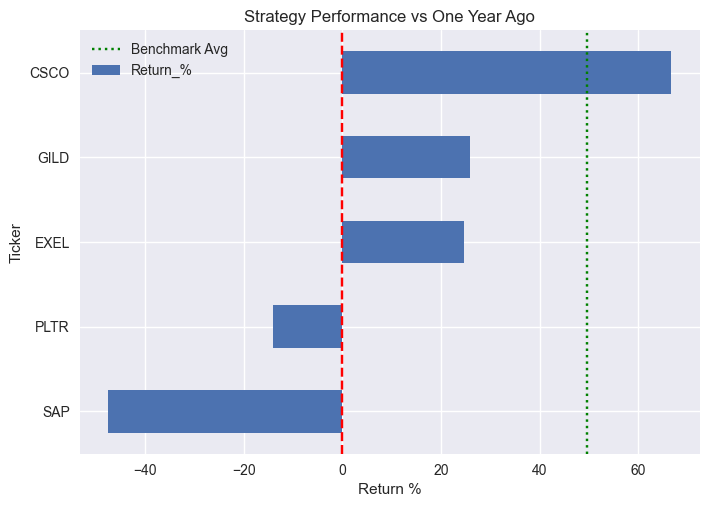

In [33]:
if backtest_results is not None:
    avg_return = backtest_results['Return_%'].mean()
    median_return = backtest_results['Return_%'].median()
    win_rate = (backtest_results['Return_%'] > 0).mean() * 100
    
    # Calculate a benchmark (Average of ALL stocks in watchlist over same period)
    # This gives us a baseline to see if the strategy beat a random pick from the list
    current_date = prices_df.index.max()
    one_year_ago = current_date - pd.DateOffset(years=1)
    
    start_prices = prices_df.loc[:one_year_ago].iloc[-1]
    end_prices = prices_df.iloc[-1]
    benchmark_returns = (end_prices / start_prices - 1) * 100
    avg_benchmark = benchmark_returns.mean()
    
    print(f"--- Backtest Summary (Past 12 Months) ---")
    print(f"Strategy Avg Return:  {avg_return:.2f}%")
    print(f"Benchmark Avg Return: {avg_benchmark:.2f}%")
    print(f"Alpha:               {avg_return - avg_benchmark:.2f}%")
    print(f"Win Rate:             {win_rate:.1f}%")
    print(f"Median Return:        {median_return:.2f}%")
    
    # Simple Plot
    backtest_results['Return_%'].sort_values().plot(kind='barh', title='Strategy Performance vs One Year Ago')
    plt.axvline(0, color='red', linestyle='--')
    plt.axvline(avg_benchmark, color='green', linestyle=':', label='Benchmark Avg')
    plt.legend()
    plt.xlabel('Return %')
    plt.show()

## 10. Reality Check: Luck, Bias, and Strategy Viability
The backtest showed significant underperformance relative to the "benchmark" (the average of all tickers in the watchlist). This raises a critical question: **Is this strategy and its statistical filters actually effective, or is it an "illusion of cleverness"?**

### 1. The Watchlist Bias (Survivorship/Selection)
The biggest risk here is **Selection Bias**. The `watchlist.csv` was likely created by looking at stocks that are *already* relevant to the AI transformation. 
*   **The Cheat**: If we test a "momentum strategy" on a list of stocks that we already know became winners over the last two years, *any* random selection from that list will likely look good.
*   **The Alpha Trap**: The benchmark (all stocks in the list) returned ~50%, while our "high conviction" picks returned ~11%. This suggests that our filters actually **removed** the highest-flying (and perhaps most volatile) winners in favor of "smoother" but lower-performing trends.

### 2. Momentum Crashes
Momentum works until it doesn't. When a theme (like AI) reaches a "crowded trade" status, the stocks with the highest $R^2$ and cleanest trends are often the ones most susceptible to a **Momentum Crash** or a rotation into value/laggards.

### 3. Strategy vs. Luck
To distinguish strategy from luck, we would need:
*   **A larger universe**: Testing on 1,000+ stocks, not just 50 hand-picked ones.
*   **Multiple time windows**: Does it work if we start in Jan, March, or September? Or only this specific July-to-July window?
*   **Risk-Adjusted Metrics**: Did the 11% return come with much lower "pain" (drawdown) than the 50% return?

Let's look at the **Volatility** and **Risk-Adjusted Return** of our picks versus the benchmark to see if we were "trading returns for safety."


--- Risk-Adjusted Comparison ---
Strategy Annual Vol: 20.10%
Benchmark Annual Vol: 21.92%
Strategy Sharpe Ratio: 0.53
Benchmark Sharpe Ratio: 1.62


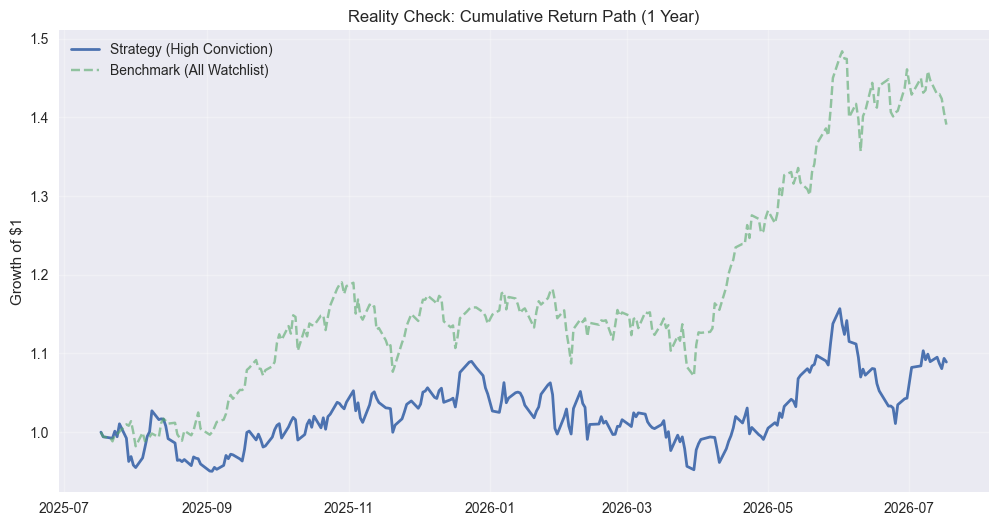

In [34]:
if backtest_results is not None:
    # Calculate daily returns for the strategy portfolio vs the entire watchlist benchmark
    # We'll assume an equal-weighted portfolio of our picks
    current_date = prices_df.index.max()
    one_year_ago = current_date - pd.DateOffset(years=1)
    
    # 1. Strategy Portfolio Daily Returns
    strat_tickers = backtest_results.index.tolist()
    strat_daily_rets = prices_df.loc[one_year_ago:, strat_tickers].pct_change().mean(axis=1)
    
    # 2. Benchmark (All Watchlist) Daily Returns
    bench_daily_rets = prices_df.loc[one_year_ago:].pct_change().mean(axis=1)
    
    # Calculate Metrics
    strat_vol = strat_daily_rets.std() * np.sqrt(252) * 100
    bench_vol = bench_daily_rets.std() * np.sqrt(252) * 100
    
    strat_sharpe = (strat_daily_rets.mean() / strat_daily_rets.std()) * np.sqrt(252) if strat_daily_rets.std() != 0 else 0
    bench_sharpe = (bench_daily_rets.mean() / bench_daily_rets.std()) * np.sqrt(252) if bench_daily_rets.std() != 0 else 0
    
    print(f"--- Risk-Adjusted Comparison ---")
    print(f"Strategy Annual Vol: {strat_vol:.2f}%")
    print(f"Benchmark Annual Vol: {bench_vol:.2f}%")
    print(f"Strategy Sharpe Ratio: {strat_sharpe:.2f}")
    print(f"Benchmark Sharpe Ratio: {bench_sharpe:.2f}")
    
    # Cumulative Return Chart
    cum_strat = (1 + strat_daily_rets.fillna(0)).cumprod()
    cum_bench = (1 + bench_daily_rets.fillna(0)).cumprod()
    
    plt.figure(figsize=(12, 6))
    plt.plot(cum_strat, label='Strategy (High Conviction)', linewidth=2)
    plt.plot(cum_bench, label='Benchmark (All Watchlist)', alpha=0.6, linestyle='--')
    plt.title('Reality Check: Cumulative Return Path (1 Year)')
    plt.ylabel('Growth of $1')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

## 11. Final Lesson: Active vs. Passive Management
The exercise we've just completed is a microcosm of the entire hedge fund industry. We built a sophisticated tool, applied statistical filters, and looked for "high conviction" winners—only to find that a simple, broad basket of stocks (the benchmark) outperformed us by a significant margin.

### The "Buy the Market" Hypothesis
Your intuition that "buying one or two low-cost ETFs and then doing something else" might be better is supported by decades of financial data.
*   **The SPIVA Data**: Standard & Poor's "Index Versus Active" (SPIVA) reports consistently show that over 10-15 year periods, **80-90% of professional active managers fail to beat their benchmark**.
*   **Cost of Complexity**: Active trading involves more screen time, potential emotional stress, and (if trading frequently) higher tax and commission costs.
*   **The Paradox of Skill**: As more "clever" people use tools like this one, the market becomes more efficient, making it even harder to find an edge.

### Conclusion
Technical analysis and momentum screening are excellent for **understanding market dynamics** and identifying specific high-potential trade ideas. However, for "real money and real returns," the core of most successful portfolios remains a low-cost, diversified index foundation. 

This notebook served its purpose not just by finding stocks, but by proving how difficult "beating the market" actually is.
